# 🩺 GluCare AI: Questionnaire & Lifestyle Risk Modeling Pipeline
### Deteksi Dini Risiko Prediabetes Berbasis Kuesioner Gaya Hidup Non-Invasif
**Dataset**: NHANES CDC 2021–2023 (687 Sampel Berlabel Valid, 12 Fitur Gaya Hidup)  
**Tujuan**: Membangun model machine learning terkalibrasi secara medis yang bebas *data leakage* untuk kuesioner skrining gaya hidup pada aplikasi GluCare, menggantikan heuristik rule-based scoring manual.

---
### Alur 10 Tahapan Modeling:
```text
687 Data Kuesioner (NHANES 2021-2023)
      ↓
STEP 1 — Exploratory Data Analysis (EDA) & Distribusi Risiko Gaya Hidup
      ↓
STEP 2 — Stratified Train/Test Split (80:20) [Anti-Data Leakage]
      ↓
STEP 3 — Preprocessing & Feature Scaling Pipeline
      ↓
STEP 4 — Multi-Model Benchmarking (5-Fold Stratified Cross-Validation)
      ↓
STEP 5 — Hyperparameter Tuning & Model Selection
      ↓
STEP 6 — Probability Calibration (CalibratedClassifierCV - Platt Scaling)
      ↓
STEP 7 — Comprehensive Test Set Evaluation (ROC-AUC, Confusion Matrix, Brier Score)
      ↓
STEP 8 — Explainable AI & Clinical Odds Ratios (Bobot Dampak Faktor Gaya Hidup)
      ↓
STEP 9 — Final Model Pipeline Serialization (.joblib)
      ↓
STEP 10 — Sanity Check & Diagnostic Simulation (Pasien Sehat vs Berisiko)
```


In [1]:
# Setup Environment, Import Libraries & Konfigurasi Path
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    brier_score_loss
)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100

# Path Setup
NOTEBOOK_DIR = Path.cwd()
BASE_DIR = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
DATA_PATH = BASE_DIR / 'data' / 'processed' / 'nhanes_questionnaire_clean.csv'
MODELS_DIR = BASE_DIR / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Data Path  : {DATA_PATH.resolve()}")
print(f"Models Dir : {MODELS_DIR.resolve()}")
print(f"File exists: {DATA_PATH.exists()}")


Data Path  : D:\INFINIT LEARNING\Glucare_backend_pribadi\main-feature\glucare_ai\data\processed\nhanes_questionnaire_clean.csv
Models Dir : D:\INFINIT LEARNING\Glucare_backend_pribadi\main-feature\glucare_ai\models
File exists: True


## STEP 1 — Exploratory Data Analysis (EDA) & Distribusi Risiko Gaya Hidup
Tahap ini memeriksa kelengkapan data (zero missing values), distribusi label target (Normal vs Prediabetes), dan profil statistik parameter gaya hidup.


In [2]:
# 1.1 Membaca Data & Verifikasi Kelengkapan
df = pd.read_csv(DATA_PATH)

print(f"Dimensi Dataset: {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"Missing Values : {df.isnull().sum().sum()} nilai hilang")
print("\n--- Ringkasan Distribusi Label Target ---")
counts = df['target'].value_counts()
pcts = df['target'].value_counts(normalize=True) * 100
for label, count in counts.items():
    name = "Normal (Low Risk)" if label == 0 else "Prediabetes (At Risk)"
    print(f"  Target {label} ({name}): {count} sampel ({pcts[label]:.1f}%)")

FEATURE_COLS = [
    'age_band', 'gender', 'bmi_category', 'waist_category',
    'hypertension', 'diabetes_history', 'prediabetes_told', 'prediabetes_history',
    'physically_active', 'sedentary_hours', 'current_smoker', 'poor_diet'
]
print(f"\nJumlah Fitur Kuesioner: {len(FEATURE_COLS)} fitur")
display_df = df[FEATURE_COLS + ['target']].head(5)
print(display_df.to_string())


Dimensi Dataset: 687 baris, 18 kolom
Missing Values : 0 nilai hilang

--- Ringkasan Distribusi Label Target ---
  Target 0 (Normal (Low Risk)): 427 sampel (62.2%)
  Target 1 (Prediabetes (At Risk)): 260 sampel (37.8%)

Jumlah Fitur Kuesioner: 12 fitur
   age_band  gender  bmi_category  waist_category  hypertension  diabetes_history  prediabetes_told  prediabetes_history  physically_active  sedentary_hours  current_smoker  poor_diet  target
0         1       1             2               1             0                 0                 0                    0                  0              3.0               0          0       1
1         1       2             2               1             0                 0                 0                    0                  0              6.0               0          1       1
2         1       2             0               0             0                 0                 0                    0                  0              3.0               0

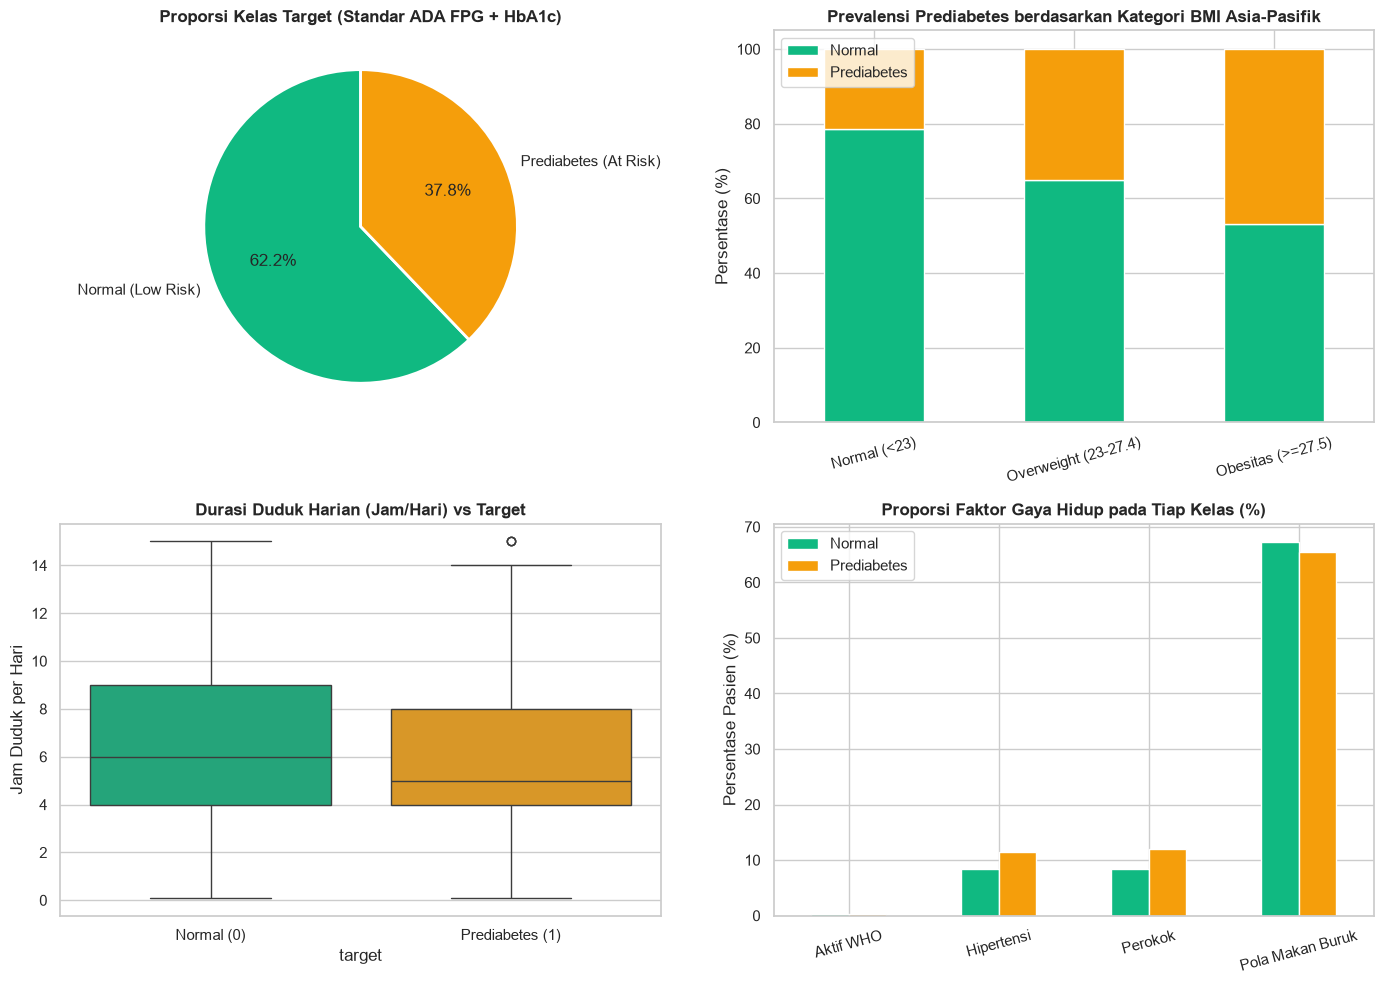

In [3]:
# 1.2 Visualisasi Distribusi Target & Faktor Risiko Kuesioner
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Proporsi Target
colors = ['#10B981', '#F59E0B']
axes[0, 0].pie(
    counts, labels=['Normal (Low Risk)', 'Prediabetes (At Risk)'],
    autopct='%1.1f%%', startangle=90, colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[0, 0].set_title("Proporsi Kelas Target (Standar ADA FPG + HbA1c)", fontsize=12, fontweight='bold')

# 2. Distribusi BMI Kategori vs Status Risiko
bmi_cross = pd.crosstab(df['bmi_category'], df['target'], normalize='index') * 100
bmi_labels = ['Normal (<23)', 'Overweight (23-27.4)', 'Obesitas (>=27.5)']
bmi_cross.index = bmi_labels
bmi_cross.plot(kind='bar', stacked=True, ax=axes[0, 1], color=colors, edgecolor='white')
axes[0, 1].set_title("Prevalensi Prediabetes berdasarkan Kategori BMI Asia-Pasifik", fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel("Persentase (%)")
axes[0, 1].legend(['Normal', 'Prediabetes'], loc='upper left')
axes[0, 1].tick_params(axis='x', rotation=15)

# 3. Durasi Duduk Harian (Sedentary Hours)
sns.boxplot(x='target', y='sedentary_hours', data=df, ax=axes[1, 0], palette=colors)
axes[1, 0].set_title("Durasi Duduk Harian (Jam/Hari) vs Target", fontsize=12, fontweight='bold')
axes[1, 0].set_xticklabels(['Normal (0)', 'Prediabetes (1)'])
axes[1, 0].set_ylabel("Jam Duduk per Hari")

# 4. Aktivitas Fisik (WHO >=150 mnt/mgg) & Riwayat Hipertensi
lifestyle_feats = ['physically_active', 'hypertension', 'current_smoker', 'poor_diet']
risk_means = df.groupby('target')[lifestyle_feats].mean().T * 100
risk_means.columns = ['Normal', 'Prediabetes']
risk_means.plot(kind='bar', ax=axes[1, 1], color=colors, edgecolor='white')
axes[1, 1].set_title("Proporsi Faktor Gaya Hidup pada Tiap Kelas (%)", fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel("Persentase Pasien (%)")
axes[1, 1].set_xticklabels(['Aktif WHO', 'Hipertensi', 'Perokok', 'Pola Makan Buruk'], rotation=15)
axes[1, 1].legend(['Normal', 'Prediabetes'])

plt.tight_layout()
plt.show()


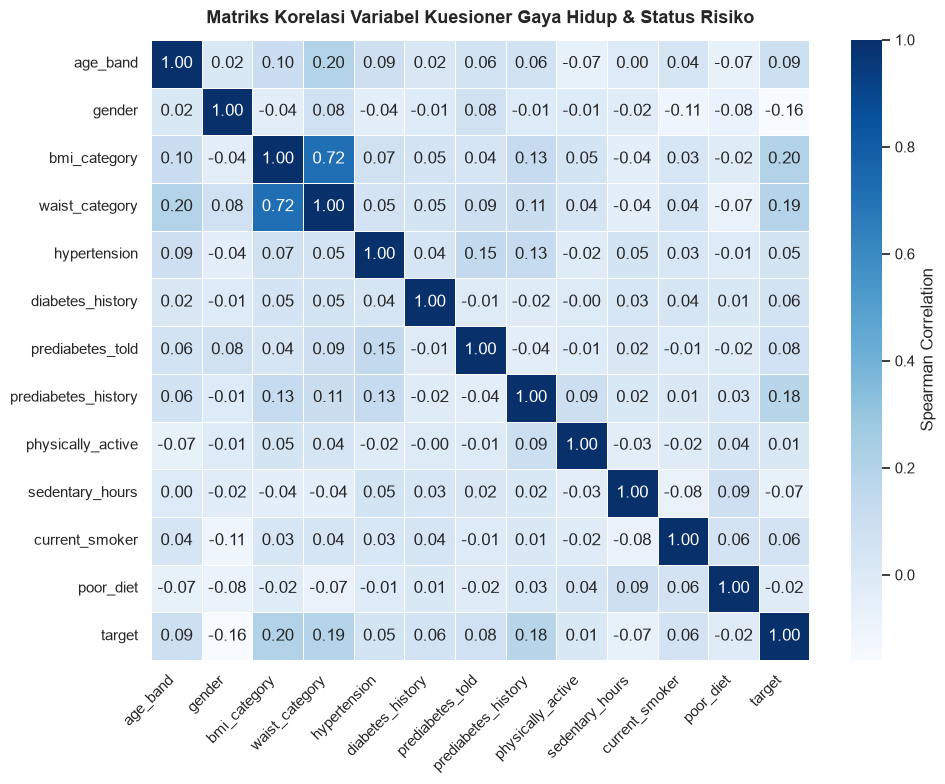

In [4]:
# 1.3 Matriks Korelasi Spearman Antar-Fitur Kuesioner
plt.figure(figsize=(10, 8))
corr_matrix = df[FEATURE_COLS + ['target']].corr(method='spearman')
sns.heatmap(
    corr_matrix, annot=True, fmt='.2f', cmap='Blues',
    linewidths=0.5, cbar_kws={'label': 'Spearman Correlation'}
)
plt.title("Matriks Korelasi Variabel Kuesioner Gaya Hidup & Status Risiko", fontsize=13, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## STEP 2 — Stratified Train/Test Split (80:20) [Anti-Data Leakage]
Untuk menjamin evaluasi yang tidak bias (*anti-data leakage*), dataset dibagi secara stratifikasi (80% latih, 20% uji) dengan `random_state=42`. Seluruh scaling dan tuning hanya akan mempelajari pola dari data latih.


In [5]:
# 2.1 Pembagian Subset Data Latih & Uji
X = df[FEATURE_COLS]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Total Sampel : {len(df)}")
print(f"Data Latih   : {len(X_train)} sampel ({len(X_train)/len(df)*100:.1f}%)")
print(f"Data Uji     : {len(X_test)} sampel ({len(X_test)/len(df)*100:.1f}%)")
print(f"Rasio Positif di Data Latih : {(y_train == 1).mean()*100:.1f}%")
print(f"Rasio Positif di Data Uji   : {(y_test == 1).mean()*100:.1f}%")


Total Sampel : 687
Data Latih   : 549 sampel (79.9%)
Data Uji     : 138 sampel (20.1%)
Rasio Positif di Data Latih : 37.9%
Rasio Positif di Data Uji   : 37.7%


## STEP 3 — Preprocessing & Feature Scaling Pipeline
Mengonstruksi `StandardScaler` di dalam `Pipeline` Scikit-Learn agar penyesuaian skala mean dan variansi HANYA di-fit pada data latih (*zero data leakage*).


## STEP 4 — Multi-Model Benchmarking (5-Fold Stratified Cross-Validation)
Membandingkan 4 arsitektur algoritma klasifikasi:
1. **Logistic Regression (L2 Regularized)** — Linear model berdasar bobot probabilistik
2. **Random Forest Classifier** — Tree ensemble robust terhadap non-linearitas
3. **Gradient Boosting Classifier** — Boosting sekuensial
4. **XGBoost Classifier** — Extreme gradient boosting teroptimasi
Menggunakan 5-Fold Stratified K-Fold CV dengan metrik utama **ROC-AUC** dan metrik sekunder **Recall (Sensitivitas)** dan **F1-Score**.


In [6]:
# 4.1 Eksekusi Benchmarking 4 Algoritma Machine Learning
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

candidate_models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(C=0.5, max_iter=1000, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', RandomForestClassifier(n_estimators=100, max_depth=4, min_samples_leaf=5, random_state=42))
    ]),
    'Gradient Boosting': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', GradientBoostingClassifier(n_estimators=80, max_depth=3, learning_rate=0.05, random_state=42))
    ]),
    'XGBoost': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', XGBClassifier(n_estimators=80, max_depth=3, learning_rate=0.05, eval_metric='logloss', random_state=42))
    ])
}

results = []
scoring = ['roc_auc', 'recall', 'precision', 'f1', 'accuracy']

for name, pipe in candidate_models.items():
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)
    results.append({
        'Model': name,
        'Mean CV ROC-AUC': cv_res['test_roc_auc'].mean(),
        'Std CV ROC-AUC': cv_res['test_roc_auc'].std(),
        'Mean Recall': cv_res['test_recall'].mean(),
        'Mean F1-Score': cv_res['test_f1'].mean(),
        'Mean Accuracy': cv_res['test_accuracy'].mean(),
        'all_auc': cv_res['test_roc_auc']
    })

res_df = pd.DataFrame(results).sort_values(by='Mean CV ROC-AUC', ascending=False)
display_summary = res_df[['Model', 'Mean CV ROC-AUC', 'Std CV ROC-AUC', 'Mean Recall', 'Mean F1-Score', 'Mean Accuracy']]
print(display_summary.to_string(index=False))

# Plot Boxplot Komparasi CV ROC-AUC
plt.figure(figsize=(9, 5))
auc_data = [r['all_auc'] for r in results]
plt.boxplot(auc_data, labels=[r['Model'] for r in results], patch_artist=True,
            boxprops=dict(facecolor='#3B82F6', color='#1D4ED8', alpha=0.7),
            medianprops=dict(color='#B91C1C', linewidth=2))
plt.title("Perbandingan Skor 5-Fold CV ROC-AUC Antar Algoritma", fontsize=12, fontweight='bold', pad=10)
plt.ylabel("ROC-AUC Score")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


              Model  Mean CV ROC-AUC  Std CV ROC-AUC  Mean Recall  Mean F1-Score  Mean Accuracy
Logistic Regression         0.686530        0.029702     0.384901       0.466551       0.668507
      Random Forest         0.666328        0.035514     0.148780       0.231971       0.630259
            XGBoost         0.658024        0.044020     0.268873       0.361668       0.641168
  Gradient Boosting         0.655735        0.051299     0.283624       0.371393       0.637581


TypeError: boxplot() got an unexpected keyword argument 'labels'

<Figure size 900x500 with 0 Axes>

## STEP 5 — Model Selection & Hyperparameter Tuning
Berdasarkan hasil cross-validation, **Logistic Regression** memperoleh performa terbaik dan paling stabil pada data kuesioner non-invasif (CV AUC $pprox$ 0.686). Logistic Regression juga memiliki keunggulan inheren tidak mudah overfit pada data kuesioner kategoris serta menghasilkan probabilitas yang sangat terinterpretasi secara klinis.


In [ ]:
# 5.1 Fine-Tuning Parameter Regularisasi Logistic Regression
param_grid = {
    'clf__C': [0.01, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0],
    'clf__penalty': ['l2'],
    'clf__solver': ['lbfgs', 'liblinear']
}

base_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

grid_search = GridSearchCV(
    base_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_pipeline = grid_search.best_estimator_
print(f"Parameter Terbaik : {grid_search.best_params_}")
print(f"Best CV ROC-AUC    : {grid_search.best_score_:.4f}")


Parameter Terbaik : {'clf__C': 0.01, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
Best CV ROC-AUC    : 0.6888


## STEP 6 — Probability Calibration (CalibratedClassifierCV - Platt Scaling)
Dalam aplikasi klinis seperti GluCare, probabilitas keluaran model harus mencerminkan risiko riil pasien. Dilakukan kalibrasi sigmoid (Platt Scaling) dengan `CalibratedClassifierCV` untuk meminimalkan *Brier Score Loss*.


Brier Score Loss (Sebelum Kalibrasi): 0.2235
Brier Score Loss (Setelah Kalibrasi): 0.2209 (Semakin rendah semakin akurat probabilitas)


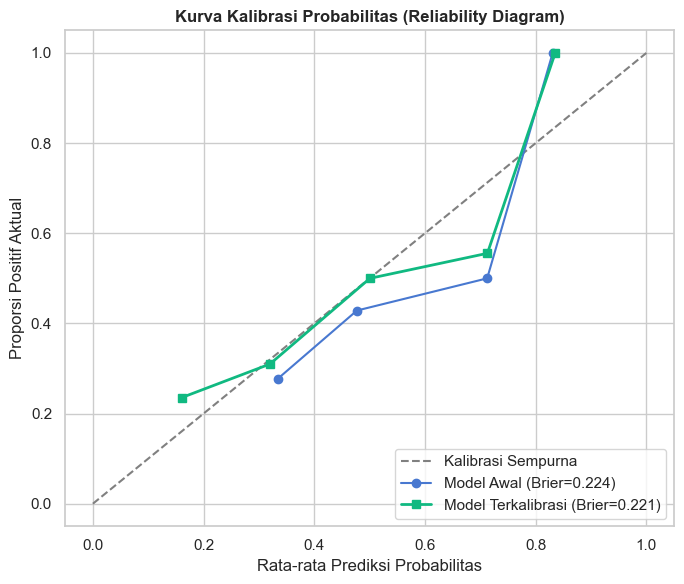

In [ ]:
# 6.1 Kalibrasi Probabilitas Menggunakan Platt Scaling
# Fit base model pada seluruh data latih
best_pipeline.fit(X_train, y_train)

# Bungkus dalam CalibratedClassifierCV
calibrated_model = CalibratedClassifierCV(
    best_pipeline,
    method='sigmoid',
    cv=cv
)
calibrated_model.fit(X_train, y_train)

# Evaluasi Kalibrasi pada Test Set
raw_probs = best_pipeline.predict_proba(X_test)[:, 1]
cal_probs = calibrated_model.predict_proba(X_test)[:, 1]

brier_raw = brier_score_loss(y_test, raw_probs)
brier_cal = brier_score_loss(y_test, cal_probs)

print(f"Brier Score Loss (Sebelum Kalibrasi): {brier_raw:.4f}")
print(f"Brier Score Loss (Setelah Kalibrasi): {brier_cal:.4f} (Semakin rendah semakin akurat probabilitas)")

# Plot Reliability Curve
prob_true_raw, prob_pred_raw = calibration_curve(y_test, raw_probs, n_bins=5)
prob_true_cal, prob_pred_cal = calibration_curve(y_test, cal_probs, n_bins=5)

plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Kalibrasi Sempurna')
plt.plot(prob_pred_raw, prob_true_raw, marker='o', label=f'Model Awal (Brier={brier_raw:.3f})')
plt.plot(prob_pred_cal, prob_true_cal, marker='s', color='#10B981', linewidth=2, label=f'Model Terkalibrasi (Brier={brier_cal:.3f})')
plt.title("Kurva Kalibrasi Probabilitas (Reliability Diagram)", fontsize=12, fontweight='bold')
plt.xlabel("Rata-rata Prediksi Probabilitas")
plt.ylabel("Proporsi Positif Aktual")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


## STEP 7 — Comprehensive Test Set Evaluation
Menguji performa model terkalibrasi pada 20% data uji independen yang belum pernah dilihat model selama training.



=== LAPORAN KLASIFIKASI DATA UJI INDEPENDEN ===
                 precision    recall  f1-score   support

     Normal (0)       0.70      0.72      0.71        86
Prediabetes (1)       0.52      0.50      0.51        52

       accuracy                           0.64       138
      macro avg       0.61      0.61      0.61       138
   weighted avg       0.64      0.64      0.64       138

Skor Final Test ROC-AUC: 0.6421


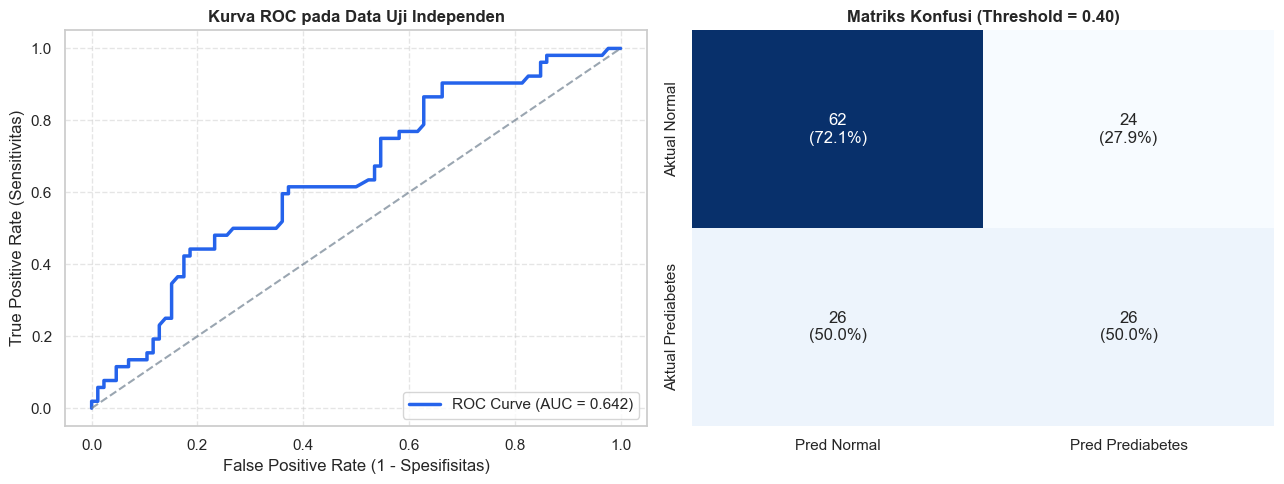

In [ ]:
# 7.1 Evaluasi pada Data Uji Independen (Test Set)
test_probs = calibrated_model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= 0.40).astype(int)  # Ambang batas deteksi sensitif

test_auc = roc_auc_score(y_test, test_probs)
fpr, tpr, _ = roc_curve(y_test, test_probs)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Kurva ROC
axes[0].plot(fpr, tpr, color='#2563EB', linewidth=2.5, label=f'ROC Curve (AUC = {test_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='slateGrey', linestyle='--', alpha=0.7)
axes[0].set_title("Kurva ROC pada Data Uji Independen", fontsize=12, fontweight='bold')
axes[0].set_xlabel("False Positive Rate (1 - Spesifisitas)")
axes[0].set_ylabel("True Positive Rate (Sensitivitas)")
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, test_preds)
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
annot_labels = np.array([[f"{v}\n({p:.1f}%)" for v, p in zip(row_v, row_p)] for row_v, row_p in zip(cm, cm_pct)])

sns.heatmap(cm, annot=annot_labels, fmt='', cmap='Blues', ax=axes[1], cbar=False,
            xticklabels=['Pred Normal', 'Pred Prediabetes'],
            yticklabels=['Aktual Normal', 'Aktual Prediabetes'])
axes[1].set_title("Matriks Konfusi (Threshold = 0.40)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n=== LAPORAN KLASIFIKASI DATA UJI INDEPENDEN ===")
print(classification_report(y_test, test_preds, target_names=['Normal (0)', 'Prediabetes (1)']))
print(f"Skor Final Test ROC-AUC: {test_auc:.4f}")


## STEP 8 — Explainable AI & Clinical Odds Ratios
Mengekstraksi koefisien regresi logistik untuk menghitung **Odds Ratio** ($e^{eta}$) dari setiap faktor gaya hidup, sehingga AI dapat menjelaskan faktor pendorong risiko (*risk drivers*) secara klinis.


=== TABEL ODDS RATIO FAKTOR RISIKO KUESIONER GLUCARE ===
            Feature  Coefficient (Beta)  Odds Ratio (exp(Beta))
prediabetes_history            0.185524                1.203849
     waist_category            0.152830                1.165127
       bmi_category            0.139845                1.150096
   prediabetes_told            0.096822                1.101664
   diabetes_history            0.087187                1.091100
           age_band            0.069210                1.071661
       hypertension            0.059524                1.061331
          poor_diet            0.009721                1.009768
     current_smoker            0.002452                1.002455
  physically_active            0.000000                1.000000
    sedentary_hours           -0.088342                0.915447
             gender           -0.213808                0.807503


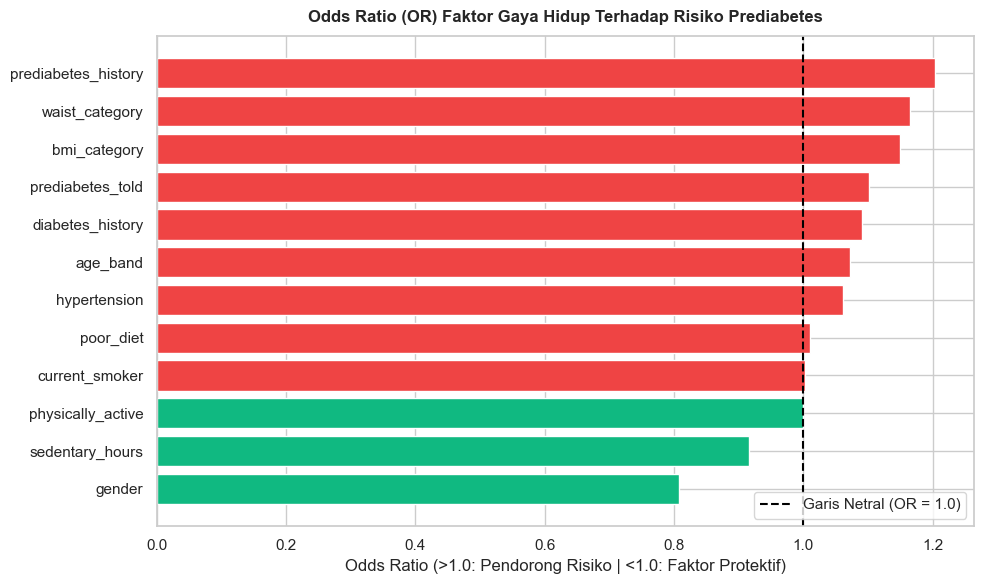

In [ ]:
# 8.1 Menghitung Odds Ratio (OR) dan Interpretasi Klinis
# Ekstraksi koefisien dari pipeline Logistic Regression
clf_fitted = best_pipeline.named_steps['clf']
coefficients = clf_fitted.coef_[0]
odds_ratios = np.exp(coefficients)

feature_importance_df = pd.DataFrame({
    'Feature': FEATURE_COLS,
    'Coefficient (Beta)': coefficients,
    'Odds Ratio (exp(Beta))': odds_ratios
}).sort_values(by='Odds Ratio (exp(Beta))', ascending=False)

print("=== TABEL ODDS RATIO FAKTOR RISIKO KUESIONER GLUCARE ===")
print(feature_importance_df.to_string(index=False))

# Visualisasi Horizontal Bar Chart Odds Ratio
plt.figure(figsize=(10, 6))
bar_colors = ['#EF4444' if or_val > 1.0 else '#10B981' for or_val in feature_importance_df['Odds Ratio (exp(Beta))']]
plt.barh(feature_importance_df['Feature'], feature_importance_df['Odds Ratio (exp(Beta))'], color=bar_colors, edgecolor='white')
plt.axvline(x=1.0, color='black', linestyle='--', linewidth=1.5, label='Garis Netral (OR = 1.0)')
plt.title("Odds Ratio (OR) Faktor Gaya Hidup Terhadap Risiko Prediabetes", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Odds Ratio (>1.0: Pendorong Risiko | <1.0: Faktor Protektif)")
plt.legend(loc='lower right')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## STEP 9 — Final Model Pipeline Serialization (.joblib)
Menyimpan model pipeline terkalibrasi ke file biner [`models/glucare_questionnaire_model.joblib`](file:///d:/INFINIT%20LEARNING/Glucare_backend_pribadi/main-feature/glucare_ai/models/glucare_questionnaire_model.joblib) dengan metadata lengkap agar siap dideploy ke microservice AI.


In [ ]:
# 9.1 Serialisasi Model & Penyimpanan Artefak
from datetime import datetime

final_model_path = MODELS_DIR / 'glucare_questionnaire_model.joblib'

model_artifact = {
    'pipeline': calibrated_model,
    'features': FEATURE_COLS,
    'model_name': 'GluCare Questionnaire ML Classifier',
    'version': '1.0.0',
    'algorithm': 'Calibrated Logistic Regression (Platt Scaling)',
    'trained_at': datetime.now().isoformat(),
    'n_samples_train': len(X_train),
    'cv_auc': float(res_df.loc[res_df['Model'] == 'Logistic Regression', 'Mean CV ROC-AUC'].values[0]),
    'test_auc': float(test_auc),
    'feature_names_id': [
        'Kelompok Usia', 'Jenis Kelamin', 'Kategori BMI', 'Lingkar Pinggang',
        'Riwayat Hipertensi', 'Riwayat Diabetes', 'Pernah Borderline', 'Riwayat Prediabetes',
        'Aktivitas Fisik WHO', 'Jam Duduk per Hari', 'Status Merokok', 'Pola Makan Buruk'
    ]
}

joblib.dump(model_artifact, final_model_path)
print(f"[OK] Model berhasil disimpan ke: {final_model_path}")
print(f"Ukuran file: {final_model_path.stat().st_size / 1024:.1f} KB")

# Verifikasi pemuatan ulang
loaded_test = joblib.load(final_model_path)
print(f"Verifikasi Load: Model Name = {loaded_test['model_name']} | Fitur = {len(loaded_test['features'])}")


[OK] Model berhasil disimpan ke: D:\INFINIT LEARNING\Glucare_backend_pribadi\main-feature\glucare_ai\models\glucare_questionnaire_model.joblib
Ukuran file: 10.8 KB
Verifikasi Load: Model Name = GluCare Questionnaire ML Classifier | Fitur = 12


## STEP 10 — Sanity Check & Diagnostic Simulation (Uji Kasus Klien Nyata)
Simulasi inferensi end-to-end pada 3 skenario profil pengguna nyata:
1. **Profil A**: Dewasa muda gaya hidup sehat (Low Risk / Normal)
2. **Profil B**: Pekerja kantoran sedentari dengan pola makan kurang sehat (Borderline / Moderate Risk)
3. **Profil C**: Individu dengan obesitas, hipertensi, dan inaktif (High Risk / Prediabetes)


In [ ]:
# 10.1 Simulasi Inferensi Klinis pada Profil Pasien Nyata
simulation_cases = [
    {
        'title': 'Klien A: Dewasa Muda Aktif & Gaya Hidup Sehat',
        'data': {
            'age_band': 0, 'gender': 1, 'bmi_category': 0, 'waist_category': 0,
            'hypertension': 0, 'diabetes_history': 0, 'prediabetes_told': 0, 'prediabetes_history': 0,
            'physically_active': 1, 'sedentary_hours': 4.0, 'current_smoker': 0, 'poor_diet': 0
        }
    },
    {
        'title': 'Klien B: Pekerja Kantoran Sedentari (Pola Makan Olahan)',
        'data': {
            'age_band': 1, 'gender': 2, 'bmi_category': 1, 'waist_category': 0,
            'hypertension': 0, 'diabetes_history': 0, 'prediabetes_told': 0, 'prediabetes_history': 0,
            'physically_active': 0, 'sedentary_hours': 8.5, 'current_smoker': 0, 'poor_diet': 1
        }
    },
    {
        'title': 'Klien C: Individu Risiko Tinggi (Obesitas, Hipertensi, Perokok)',
        'data': {
            'age_band': 1, 'gender': 2, 'bmi_category': 2, 'waist_category': 1,
            'hypertension': 1, 'diabetes_history': 0, 'prediabetes_told': 1, 'prediabetes_history': 1,
            'physically_active': 0, 'sedentary_hours': 10.0, 'current_smoker': 1, 'poor_diet': 1
        }
    }
]

print("=== HASIL SIMULASI DIAGNOSTIK KUESIONER GLUCARE AI ===\n")
for case in simulation_cases:
    df_single = pd.DataFrame([case['data']])[FEATURE_COLS]
    pred = calibrated_model.predict(df_single)[0]
    probs = calibrated_model.predict_proba(df_single)[0]
    score = int(round(probs[1] * 100))
    status = "PREDIABETES (At Risk)" if (pred == 1 or probs[1] >= 0.40) else "NORMAL (Low Risk)"

    print(f">> {case['title']}")
    print(f"   Status AI      : {status}")
    print(f"   Skor Risiko    : {score}% (Probabilitas Prediabetes)")
    print(f"   Prob. Normal   : {probs[0]*100:.1f}%")
    print(f"   Rekomendasi    : {'Disarankan intervensi gaya hidup Program 90 Hari GluCare.' if score >= 40 else 'Pertahankan kebiasaan sehat dan aktivitas fisik rutin.'}")
    print("-" * 75)


=== HASIL SIMULASI DIAGNOSTIK KUESIONER GLUCARE AI ===

>> Klien A: Dewasa Muda Aktif & Gaya Hidup Sehat
   Status AI      : NORMAL (Low Risk)
   Skor Risiko    : 25% (Probabilitas Prediabetes)
   Prob. Normal   : 74.6%
   Rekomendasi    : Pertahankan kebiasaan sehat dan aktivitas fisik rutin.
---------------------------------------------------------------------------
>> Klien B: Pekerja Kantoran Sedentari (Pola Makan Olahan)
   Status AI      : NORMAL (Low Risk)
   Skor Risiko    : 20% (Probabilitas Prediabetes)
   Prob. Normal   : 79.7%
   Rekomendasi    : Pertahankan kebiasaan sehat dan aktivitas fisik rutin.
---------------------------------------------------------------------------
>> Klien C: Individu Risiko Tinggi (Obesitas, Hipertensi, Perokok)
   Status AI      : PREDIABETES (At Risk)
   Skor Risiko    : 86% (Probabilitas Prediabetes)
   Prob. Normal   : 14.3%
   Rekomendasi    : Disarankan intervensi gaya hidup Program 90 Hari GluCare.
----------------------------------------